<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/2_quantum/susy_qm/susyqm_visualizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Supersymmetric Quantum Mechanics* — `susyqm_visualizations.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Supersymmetric Quantum Mechanics — Colab Visualization Notebook
**Based on D. Tong, DAMTP Cambridge · susyqm.pdf**

This notebook produces **7 self-contained visualizations** spanning all three chapters.
Each cell is independent; run Setup (Cell 2) first, then any figure cell.

| Plot | Chapter | Topic |
|------|---------|-------|
| 1 | Ch 1 §1.1 | Energy spectrum: bosonic/fermionic pairing and the Witten index |
| 2 | Ch 1 §1.2 | Superpotential gallery: h(x), V(x), and exact ground states |
| 3 | Ch 1 §1.2 | Witten index vs β — independence and β→∞ limit |
| 4 | Ch 2 §2.1 | Path integral boundary conditions: periodic vs anti-periodic on S¹ |
| 5 | Ch 2 §2.2 | Instanton kink x(τ)=tanh, dilute gas energy shift vs instanton action |
| 6 | Ch 3 §3.1 | de Rham cohomology: Betti numbers and χ(M) for compact manifolds |
| 7 | Ch 3 §3.2 | Morse theory: gradient flow lines and Morse–Witten complex on T² |


In [1]:
# ── Setup: run this cell first ───────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
from scipy.special import erf
import os

BG   = '#1e1e2e'; FG = '#cdd6f4'; EDGE = '#45475a'
PURP = '#c792ea'; BLUE = '#7ec8e3'; YELL = '#f9c74f'
GREEN= '#90ee90'; RED  = '#e07070'; ORAN = '#e8a838'; TEAL = '#2ec4b6'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'text.color': FG, 'axes.labelcolor': FG,
    'xtick.color': FG, 'ytick.color': FG,
    'axes.edgecolor': EDGE, 'grid.color': EDGE, 'grid.alpha': 0.3,
    'font.size': 12, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlecolor': PURP, 'legend.framealpha': 0.3,
    'legend.edgecolor': EDGE, 'lines.linewidth': 2.2,
    'axes.linewidth': 1.2, 'figure.dpi': 110,
})

os.makedirs('susyqm_figures', exist_ok=True)

def savefig(name):
    plt.savefig(f'susyqm_figures/{name}', dpi=150, bbox_inches='tight', facecolor=BG)
    plt.show()
    print(f'Saved: susyqm_figures/{name}')

print('Setup complete. Run any plot cell below.')


Setup complete. Run any plot cell below.


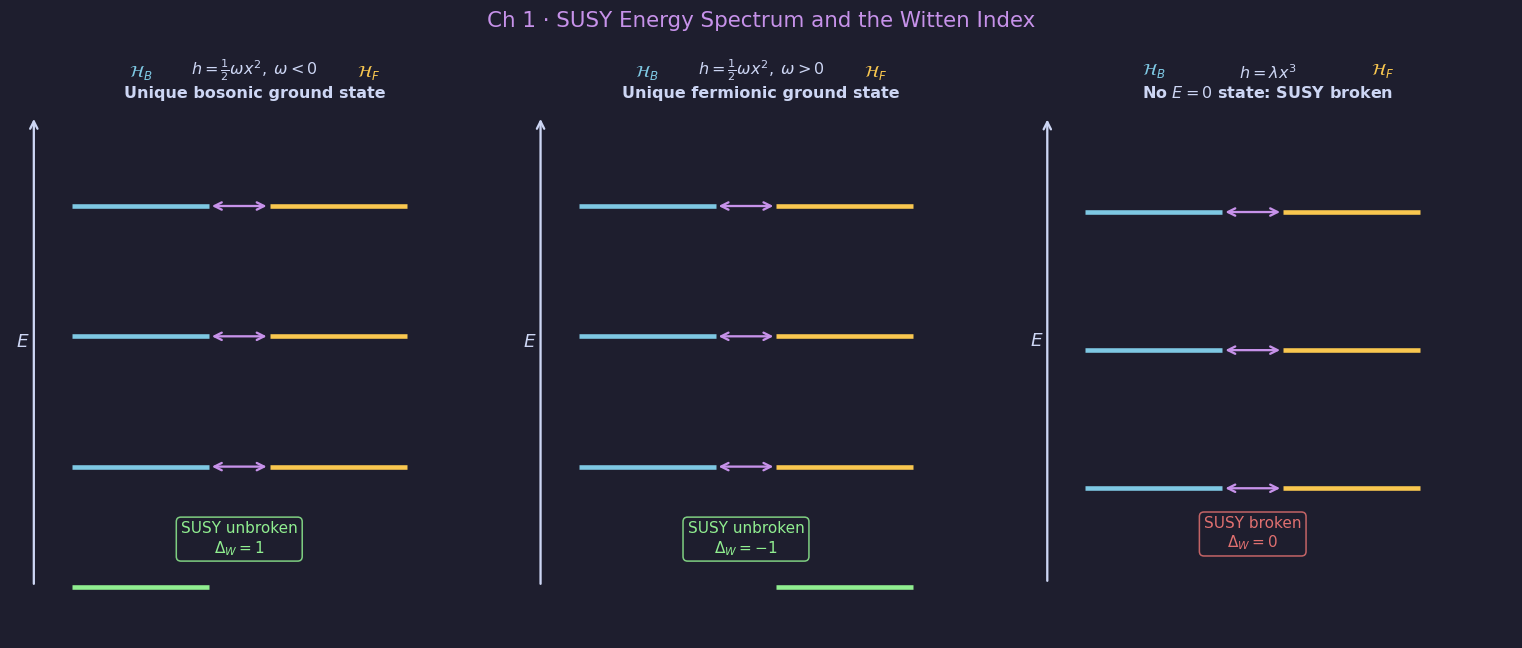

Saved: susyqm_figures/plot1_spectrum.png


In [2]:
# ── Plot 1: Energy spectrum — boson/fermion pairing and Witten index ─────────
fig, axes = plt.subplots(1, 3, figsize=(14, 6))
fig.suptitle('Ch 1 · SUSY Energy Spectrum and the Witten Index', color=PURP, fontsize=14)

def spectrum_panel(ax, title, energies_B, energies_F, Delta_W, susy='unbroken'):
    ax.set_facecolor(BG); ax.axis('off')
    ax.set_title(title, color=FG, fontsize=10.5)
    ax.set_xlim(0, 3.2); ax.set_ylim(-0.5, max(max(energies_B), max(energies_F, default=0))+1)
    # y-axis
    ax.annotate('', xy=(0.15, ax.get_ylim()[1]-0.1), xytext=(0.15, 0),
                arrowprops=dict(arrowstyle='->', color=FG, lw=1.5))
    ax.text(0.08, ax.get_ylim()[1]/2, r'$E$', ha='center', fontsize=12, color=FG)
    ax.text(0.85, ax.get_ylim()[1]+0.3, r'$\mathcal{H}_B$',
            ha='center', fontsize=11, color=BLUE, fontweight='bold')
    ax.text(2.35, ax.get_ylim()[1]+0.3, r'$\mathcal{H}_F$',
            ha='center', fontsize=11, color=YELL, fontweight='bold')
    for E in energies_B:
        col = GREEN if E == 0 else BLUE
        ax.hlines(E, 0.4, 1.3, colors=col, lw=3)
    for E in energies_F:
        col = GREEN if E == 0 else YELL
        ax.hlines(E, 1.7, 2.6, colors=col, lw=3)
    # pair arrows
    paired = sorted(set(energies_B) & set(energies_F))
    for E in paired:
        ax.annotate('', xy=(1.7, E), xytext=(1.3, E),
                    arrowprops=dict(arrowstyle='<->', color=PURP, lw=1.5))
    col_s = GREEN if susy == 'unbroken' else RED
    label = f'SUSY {susy}\n' + r'$\Delta_W=' + str(Delta_W) + r'$'
    ax.text(1.5, 0.35, label, ha='center', fontsize=10, color=col_s,
            bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=col_s, alpha=0.85))

# Panel 1: unbroken, unique bosonic GS
spectrum_panel(axes[0], r'$h=\frac{1}{2}\omega x^2,\;\omega<0$'+
               '\nUnique bosonic ground state',
               [0, 1.2, 2.5, 3.8], [1.2, 2.5, 3.8], +1, 'unbroken')

# Panel 2: unbroken, unique fermionic GS
spectrum_panel(axes[1], r'$h=\frac{1}{2}\omega x^2,\;\omega>0$'+
               '\nUnique fermionic ground state',
               [1.2, 2.5, 3.8], [0, 1.2, 2.5, 3.8], -1, 'unbroken')

# Panel 3: broken, no GS
spectrum_panel(axes[2], r'$h=\lambda x^3$'+
               '\nNo $E=0$ state: SUSY broken',
               [0.9, 2.2, 3.5], [0.9, 2.2, 3.5], 0, 'broken')

plt.tight_layout()
savefig('plot1_spectrum.png')


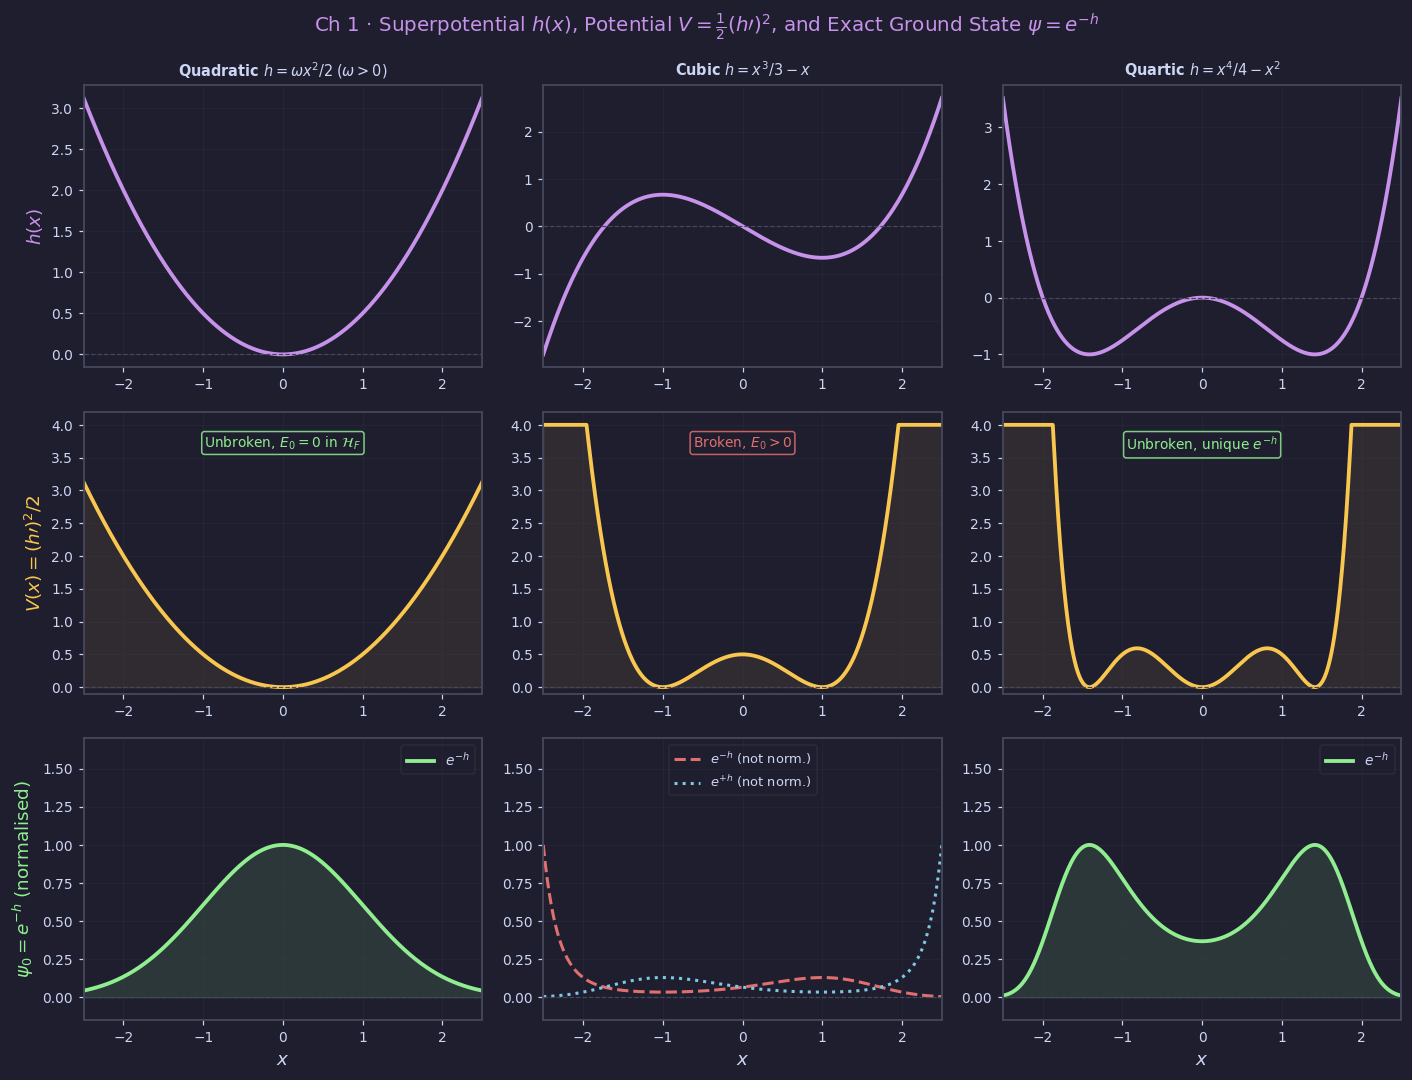

Saved: susyqm_figures/plot2_superpotential_gallery.png


In [3]:
# ── Plot 2: Superpotential gallery — h(x), V(x), and ground states ───────────
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
fig.suptitle(r'Ch 1 · Superpotential $h(x)$, Potential $V=\frac{1}{2}(h\prime)^2$,'
             r' and Exact Ground State $\psi=e^{-h}$', color=PURP, fontsize=13)

x = np.linspace(-2.5, 2.5, 600)

cases = [
    # (name, h(x), h'(x), omega, label_status)
    (r'Quadratic $h=\omega x^2/2\;(\omega>0)$',
     0.5*x**2, x, r'Unbroken, $E_0=0$ in $\mathcal{H}_F$'),
    (r'Cubic $h=x^3/3-x$',
     x**3/3 - x, x**2-1, 'Broken, $E_0>0$'),
    (r'Quartic $h=x^4/4-x^2$',
     x**4/4 - x**2, x**3-2*x, r'Unbroken, unique $e^{-h}$'),
]

for col, (name, h, hp, status) in enumerate(cases):
    V  = 0.5 * hp**2
    psi = np.exp(-h); psi /= np.max(np.abs(psi)) + 1e-9

    # Row 0: h(x)
    ax = axes[0, col]; ax.set_facecolor(BG)
    if col == 0: ax.set_ylabel(r'$h(x)$', color=PURP)
    ax.set_title(name, color=FG, fontsize=9.5)
    ax.plot(x, h, color=PURP, lw=2.5)
    ax.axhline(0, color=EDGE, lw=0.8, ls='--')
    ax.set_xlim(-2.5, 2.5); ax.tick_params(labelsize=9)

    # Row 1: V(x)
    ax = axes[1, col]; ax.set_facecolor(BG)
    if col == 0: ax.set_ylabel(r'$V(x)=(h\prime)^2/2$', color=YELL)
    Vc = np.clip(V, 0, 4)
    ax.plot(x, Vc, color=YELL, lw=2.5)
    ax.fill_between(x, 0, Vc, color=YELL, alpha=0.08)
    ax.axhline(0, color=EDGE, lw=0.8, ls='--')
    ax.set_xlim(-2.5, 2.5); ax.set_ylim(-0.1, 4.2); ax.tick_params(labelsize=9)
    col_s = GREEN if 'Unbroken' in status else RED
    ax.text(0.5, 0.92, status, transform=ax.transAxes, ha='center', va='top',
            fontsize=9, color=col_s,
            bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=col_s, alpha=0.85))

    # Row 2: ground state
    ax = axes[2, col]; ax.set_facecolor(BG)
    if col == 0: ax.set_ylabel(r'$\psi_0=e^{-h}$ (normalised)', color=GREEN)
    ax.set_xlabel(r'$x$')
    if 'Broken' in status:
        ax.plot(x, np.clip(psi, -1.5, 1.5), color=RED, lw=2, ls='--',
                label=r'$e^{-h}$ (not norm.)')
        anti = np.exp(h); anti /= np.max(np.abs(anti)) + 1e-9
        ax.plot(x, np.clip(anti, -1.5, 1.5), color=BLUE, lw=2, ls=':',
                label=r'$e^{+h}$ (not norm.)')
        ax.legend(fontsize=8.5, loc='upper center')
    else:
        psic = np.clip(psi, 0, 1.5)
        ax.plot(x, psic, color=GREEN, lw=2.5, label=r'$e^{-h}$')
        ax.fill_between(x, 0, psic, color=GREEN, alpha=0.12)
        ax.legend(fontsize=9)
    ax.axhline(0, color=EDGE, lw=0.8, ls='--')
    ax.set_xlim(-2.5, 2.5); ax.set_ylim(-0.15, 1.7); ax.tick_params(labelsize=9)

for ax in axes.flat: ax.grid(True, alpha=0.15)
plt.tight_layout()
savefig('plot2_superpotential_gallery.png')


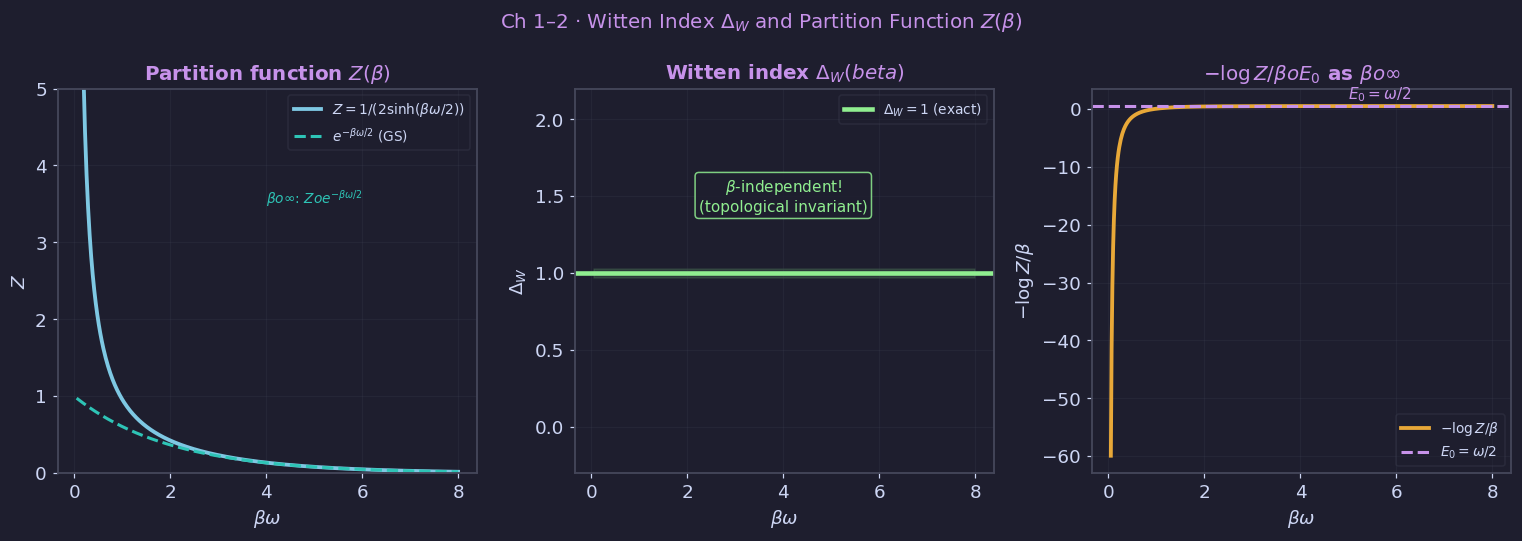

Saved: susyqm_figures/plot3_witten_index_beta.png


In [4]:
# ── Plot 3: Witten index vs β and partition function ─────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle(r'Ch 1–2 · Witten Index $\Delta_W$ and Partition Function $Z(\beta)$',
             color=PURP, fontsize=13)

omega = 1.0
beta  = np.linspace(0.05, 8, 500)

# Exact Z = 1/(2 sinh(βω/2))
Z_exact = 1.0 / (2 * np.sinh(beta * omega / 2))
# Large-β: Z ≈ e^{-βω/2}
Z_gs    = np.exp(-beta * omega / 2)
# Witten index = 1 (for ω>0, unique fermionic GS)
Delta_W = np.ones_like(beta)

ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'Partition function $Z(\beta)$', color=PURP)
ax.plot(beta, Z_exact, color=BLUE, lw=2.5, label=r'$Z=1/(2\sinh(\beta\omega/2))$')
ax.plot(beta, Z_gs, color=TEAL, lw=2, ls='--', label=r'$e^{-\beta\omega/2}$ (GS)')
ax.set_xlabel(r'$\beta\omega$'); ax.set_ylabel(r'$Z$')
ax.legend(fontsize=9); ax.grid(True, alpha=0.2); ax.set_ylim(0, 5)
ax.text(4, 3.5, r'$\beta\to\infty$: $Z\to e^{-\beta\omega/2}$', fontsize=9, color=TEAL)

ax = axes[1]; ax.set_facecolor(BG)
ax.set_title(r'Witten index $\Delta_W(beta)$', color=PURP)
ax.axhline(1, color=GREEN, lw=3, label=r'$\Delta_W=1$ (exact)')
ax.fill_between(beta, 0.97, 1.03, color=GREEN, alpha=0.12)
ax.set_xlabel(r'$\beta\omega$'); ax.set_ylabel(r'$\Delta_W$')
ax.set_ylim(-0.3, 2.2); ax.grid(True, alpha=0.2); ax.legend(fontsize=9)
ax.text(4, 1.4, r'$\beta$-independent!' + '\n(topological invariant)',
        ha='center', fontsize=10, color=GREEN,
        bbox=dict(boxstyle='round,pad=0.25', fc=BG, ec=GREEN, alpha=0.85))

# Panel 3: log Z vs beta — extract ground state energy
ax = axes[2]; ax.set_facecolor(BG)
ax.set_title(r'$-\log Z / \beta \to E_0$ as $\beta\to\infty$', color=PURP)
E_extract = -np.log(Z_exact) / beta
ax.plot(beta, E_extract, color=ORAN, lw=2.5, label=r'$-\log Z/\beta$')
ax.axhline(omega/2, color=PURP, lw=2, ls='--', label=r'$E_0=\omega/2$')
ax.set_xlabel(r'$\beta\omega$'); ax.set_ylabel(r'$-\log Z/\beta$')
ax.legend(fontsize=9); ax.grid(True, alpha=0.2)
ax.text(5, omega/2 + 1.2, r'$E_0=\omega/2$', color=PURP, fontsize=10)

plt.tight_layout()
savefig('plot3_witten_index_beta.png')


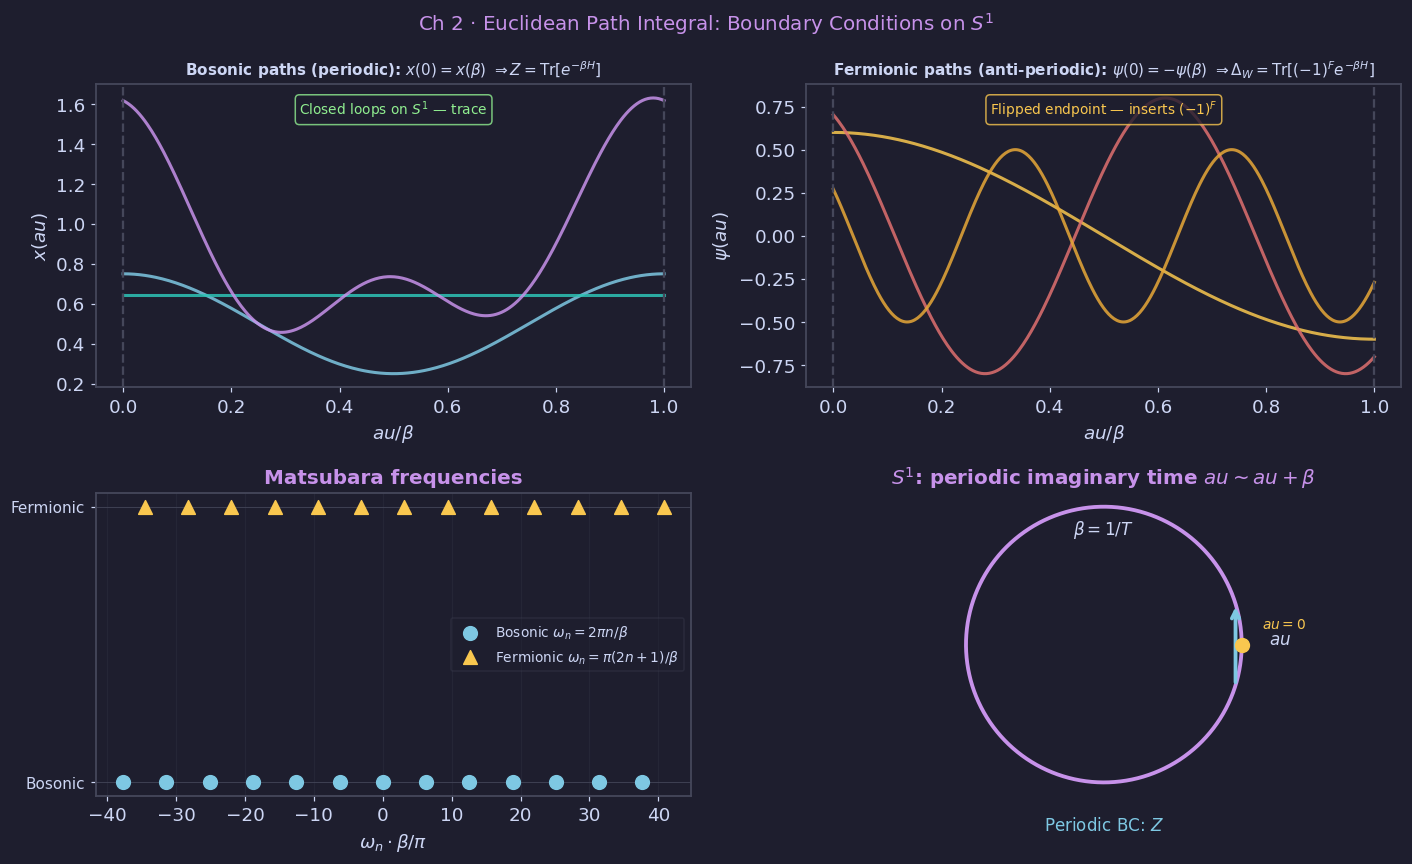

Saved: susyqm_figures/plot4_path_integral_bc.png


In [5]:
# ── Plot 4: Path integral boundary conditions on S¹ ─────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
fig.suptitle(r'Ch 2 · Euclidean Path Integral: Boundary Conditions on $S^1$',
             color=PURP, fontsize=13)

tau = np.linspace(0, 1, 400)  # τ/β ∈ [0,1]

# Periodic bosonic paths
ax = axes[0, 0]; ax.set_facecolor(BG)
ax.set_title(r'Bosonic paths (periodic): $x(0)=x(\beta)$' +' '+r'$\Rightarrow Z=\mathrm{Tr}[e^{-\beta H}]$', color=FG, fontsize=10)
rng = np.random.default_rng(42)
for amp, freq, ph, col in [(0.5,2,0,BLUE),(0.7,1,0.4,TEAL),(0.9,3,0.2,PURP)]:
    modes = [amp * np.cos(2*np.pi*n*tau + ph) / (n+1) for n in range(freq)]
    y = sum(modes); y -= y[0] - y[-1]  # enforce periodicity
    ax.plot(tau, y, color=col, lw=2, alpha=0.85)
ax.axvline(0, color=EDGE, lw=1.5, ls='--'); ax.axvline(1, color=EDGE, lw=1.5, ls='--')
ax.set_xlabel(r'$\tau/\beta$'); ax.set_ylabel(r'$x(\tau)$')
ax.text(0.5, 0.90, 'Closed loops on $S^1$ — trace',
        ha='center', transform=ax.transAxes, fontsize=9, color=GREEN,
        bbox=dict(boxstyle='round', fc=BG, ec=GREEN, alpha=0.8))

# Anti-periodic fermionic paths
ax = axes[0, 1]; ax.set_facecolor(BG)
ax.set_title(r'Fermionic paths (anti-periodic): $\psi(0)=-\psi(\beta)$'+' '+r'$\Rightarrow \Delta_W=\mathrm{Tr}[(-1)^F e^{-\beta H}]$', color=FG, fontsize=10)
for amp, n_half, ph, col in [(0.6,1,0,YELL),(0.8,2,0.5,RED),(0.5,3,1.0,ORAN)]:
    y = amp * np.cos(np.pi*(2*n_half-1)*tau + ph)
    ax.plot(tau, y, color=col, lw=2, alpha=0.85)
ax.axvline(0, color=EDGE, lw=1.5, ls='--'); ax.axvline(1, color=EDGE, lw=1.5, ls='--')
ax.set_xlabel(r'$\tau/\beta$'); ax.set_ylabel(r'$\psi(\tau)$')
ax.text(0.5, 0.90, r'Flipped endpoint — inserts $(-1)^F$',
        ha='center', transform=ax.transAxes, fontsize=9, color=YELL,
        bbox=dict(boxstyle='round', fc=BG, ec=YELL, alpha=0.8))

# Matsubara frequencies
ax = axes[1, 0]; ax.set_facecolor(BG)
ax.set_title('Matsubara frequencies', color=PURP)
ns = np.arange(-6, 7)
wB = 2 * np.pi * ns          # bosonic: even multiples
wF = np.pi * (2*ns + 1)       # fermionic: odd multiples
ax.scatter(wB, np.zeros_like(wB), color=BLUE, s=80, zorder=5, label=r'Bosonic $\omega_n=2\pi n/\beta$')
ax.scatter(wF, np.ones_like(wF)*0.4, color=YELL, s=80, marker='^', zorder=5,
           label=r'Fermionic $\omega_n=\pi(2n+1)/\beta$')
ax.axhline(0, color=EDGE, lw=0.5)
ax.axhline(0.4, color=EDGE, lw=0.5)
ax.set_yticks([0, 0.4]); ax.set_yticklabels(['Bosonic', 'Fermionic'], fontsize=10)
ax.set_xlabel(r'$\omega_n \cdot \beta / \pi$'); ax.legend(fontsize=9)
ax.grid(True, alpha=0.2)

# Schematic: S¹ circle with arrows
ax = axes[1, 1]; ax.set_facecolor(BG); ax.set_aspect('equal'); ax.axis('off')
ax.set_title(r'$S^1$: periodic imaginary time $\tau\sim\tau+\beta$', color=PURP)
th = np.linspace(0, 2*np.pi, 300)
ax.plot(np.cos(th), np.sin(th), color=PURP, lw=2.5)
# Periodic arrow (same color)
ax.annotate('', xy=(np.cos(0.3), np.sin(0.3)), xytext=(np.cos(-0.3), np.sin(-0.3)),
            arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.5))
ax.text(0, -1.35, r'Periodic BC: $Z$', ha='center', fontsize=11, color=BLUE)
ax.text(0, 0.8, r'$\beta = 1/T$', ha='center', fontsize=11, color=FG)
ax.text(1.2, 0, r'$\tau$', ha='left', fontsize=11, color=FG)
# Mark points
ax.plot([1], [0], 'o', color=YELL, ms=9, zorder=6)
ax.text(1.15, 0.12, r'$\tau=0$', fontsize=9, color=YELL)

plt.tight_layout()
savefig('plot4_path_integral_bc.png')


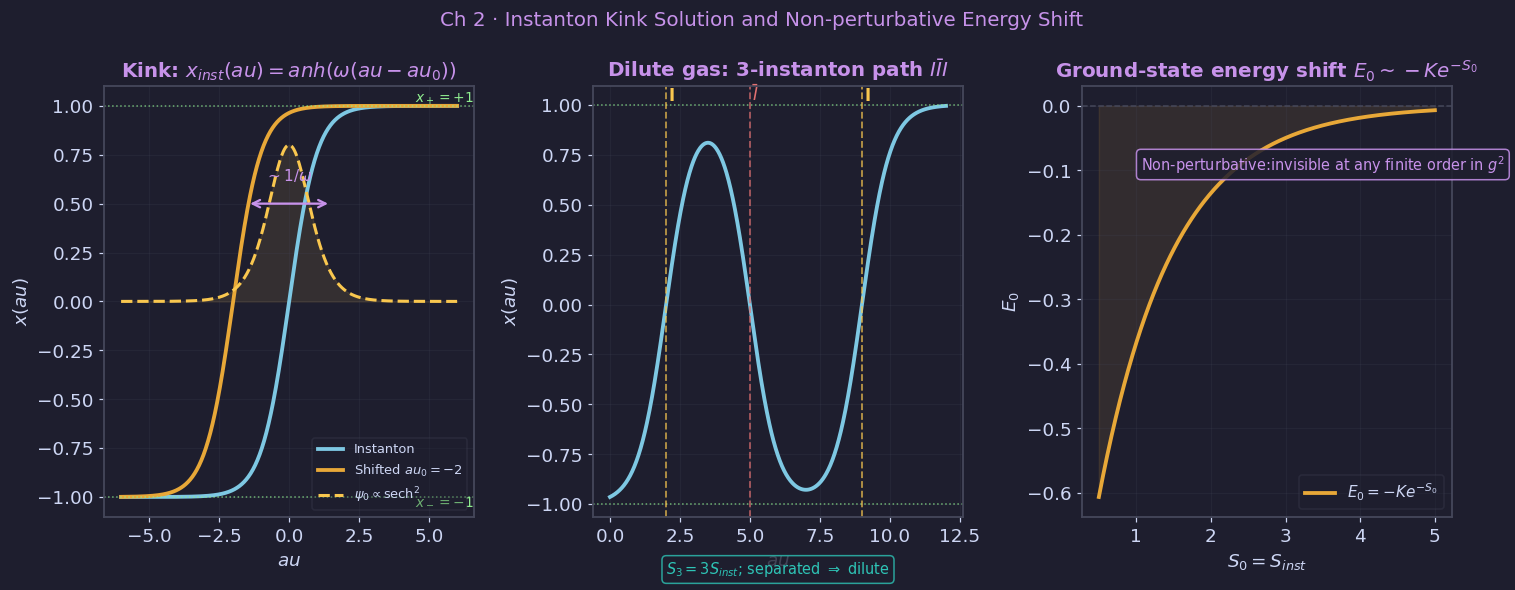

Saved: susyqm_figures/plot5_instanton.png


In [6]:
# ── Plot 5: Instanton kink and dilute gas energy shift ───────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5.5))
fig.suptitle('Ch 2 · Instanton Kink Solution and Non-perturbative Energy Shift',
             color=PURP, fontsize=13)

tau = np.linspace(-6, 6, 600)

# Panel 1: instanton profile
ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'Kink: $x_{inst}(\tau)=\tanh(\omega(\tau-\tau_0))$', color=PURP)
for tau0, col, lbl in [(0, BLUE, 'Instanton'), (-2, ORAN, r'Shifted $\tau_0=-2$')]:
    ax.plot(tau, np.tanh(tau - tau0), color=col, lw=2.5, label=lbl)
ax.axhline(1, color=GREEN, lw=1, ls=':', alpha=0.7)
ax.axhline(-1, color=GREEN, lw=1, ls=':', alpha=0.7)
ax.text(4.5, 1.02, r'$x_+=+1$', color=GREEN, fontsize=9)
ax.text(4.5,-1.04, r'$x_-=-1$', color=GREEN, fontsize=9)
# Fermi zero mode
psi0 = 1.0 / np.cosh(tau)**2; psi0 /= psi0.max()
ax.plot(tau, psi0 * 0.8, color=YELL, lw=2, ls='--', label=r'$\psi_0\propto\mathrm{sech}^2$')
ax.fill_between(tau, 0, psi0*0.8, color=YELL, alpha=0.10)
ax.set_xlabel(r'$\tau$'); ax.set_ylabel(r'$x(\tau)$')
ax.legend(fontsize=8.5); ax.grid(True, alpha=0.2)
ax.annotate('', xy=(1.5, 0.5), xytext=(-1.5, 0.5),
            arrowprops=dict(arrowstyle='<->', color=PURP, lw=1.5))
ax.text(0, 0.62, r'$\sim 1/\omega$', ha='center', fontsize=10, color=PURP)

# Panel 2: dilute gas — multi-instanton path
ax = axes[1]; ax.set_facecolor(BG)
ax.set_title(r'Dilute gas: 3-instanton path $I\bar{I}I$', color=PURP)
tau_long = np.linspace(0, 12, 800)
centers = [2, 5, 9]; signs = [+1, -1, +1]
x_path = -np.ones_like(tau_long)
for c, s in zip(centers, signs):
    x_path += s * (np.tanh(tau_long - c) + 1)
x_path = np.clip(x_path, -1.2, 1.2)
ax.plot(tau_long, x_path, color=BLUE, lw=2.5)
ax.axhline(1, color=GREEN, lw=1, ls=':', alpha=0.7)
ax.axhline(-1, color=GREEN, lw=1, ls=':', alpha=0.7)
for c, s, col in zip(centers, signs, [YELL, RED, YELL]):
    ax.axvline(c, color=col, lw=1.2, ls='--', alpha=0.7)
    ax.text(c +0.2, 1.02, 'I' if s>0 else r'$\bar{I}$', ha='center', fontsize=11,
            color=col, fontweight='bold')
ax.set_xlabel(r'$\tau$'); ax.set_ylabel(r'$x(\tau)$')
ax.text(6, -1.35, r'$S_3=3S_{inst}$; separated $\Rightarrow$ dilute',
        ha='center', fontsize=9.5, color=TEAL,
        bbox=dict(boxstyle='round', fc=BG, ec=TEAL, alpha=0.8))
ax.grid(True, alpha=0.2)

# Panel 3: E₀ vs S₀ (instanton action)
ax = axes[2]; ax.set_facecolor(BG)
ax.set_title(r'Ground-state energy shift $E_0\sim -Ke^{-S_0}$', color=PURP)
S0 = np.linspace(0.5, 5, 400)
K  = 1.0
E0 = -K * np.exp(-S0)
ax.plot(S0, E0, color=ORAN, lw=2.5, label=r'$E_0=-Ke^{-S_0}$')
ax.axhline(0, color=EDGE, lw=1, ls='--')
ax.fill_between(S0, E0, 0, color=ORAN, alpha=0.10)
ax.set_xlabel(r'$S_0 = S_{inst}$'); ax.set_ylabel(r'$E_0$')
ax.legend(fontsize=10); ax.grid(True, alpha=0.2)
ax.text(3.5, -0.1, 'Non-perturbative:' + r'invisible at any finite order in $g^2$',
        ha='center', fontsize=9.5, color=PURP,
        bbox=dict(boxstyle='round', fc=BG, ec=PURP, alpha=0.85))

plt.tight_layout()
savefig('plot5_instanton.png')


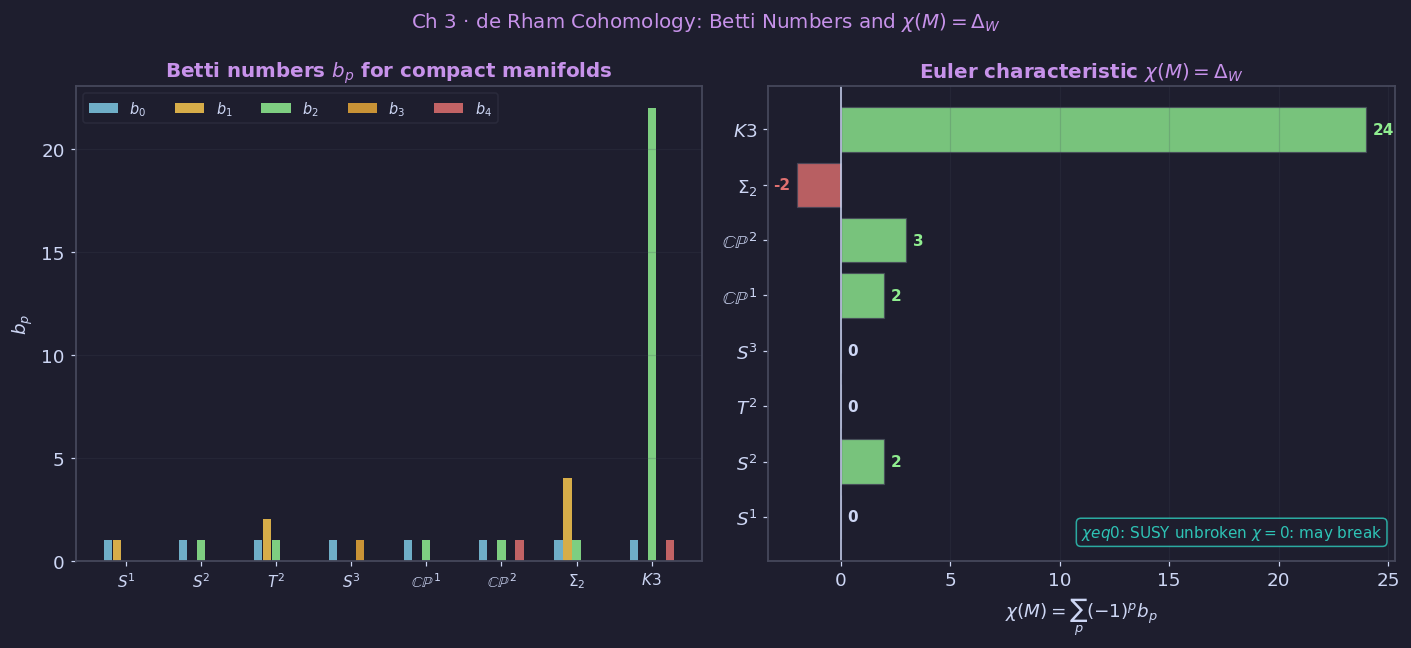

Saved: susyqm_figures/plot6_betti_euler.png


In [7]:
# ── Plot 6: de Rham cohomology — Betti numbers and χ(M) ─────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
fig.suptitle(r'Ch 3 · de Rham Cohomology: Betti Numbers and $\chi(M)=\Delta_W$',
             color=PURP, fontsize=13)

manifolds = [
    (r'$S^1$',   [1,1],   0,  'torus¹',   BLUE),
    (r'$S^2$',   [1,0,1], 2,  'sphere²',  PURP),
    (r'$T^2$',   [1,2,1], 0,  'torus²',   TEAL),
    (r'$S^3$',   [1,0,0,1], 0,'sphere³',  GREEN),
    (r'$\mathbb{CP}^1$', [1,0,1], 2, 'CP1', ORAN),
    (r'$\mathbb{CP}^2$', [1,0,1,0,1], 3, 'CP2', RED),
    (r'$\Sigma_2$', [1,4,1], -2, 'genus-2', YELL),
    (r'$K3$',    [1,0,22,0,1], 24, 'K3', BLUE),
]

# Left: bar chart of Betti numbers
ax = axes[0]; ax.set_facecolor(BG)
ax.set_title('Betti numbers $b_p$ for compact manifolds', color=PURP)
x_pos = np.arange(len(manifolds))
w = 0.12; max_p = 4
colors_bar = [BLUE, YELL, GREEN, ORAN, RED]
for p in range(max_p+1):
    bps = []
    for (name, betti, chi, tag, col) in manifolds:
        bps.append(betti[p] if p < len(betti) else 0)
    ax.bar(x_pos + (p - max_p/2)*w, bps, w*0.9,
           color=colors_bar[p], alpha=0.85, label=f'$b_{p}$')

ax.set_xticks(x_pos)
ax.set_xticklabels([m[0] for m in manifolds], fontsize=10)
ax.set_ylabel(r'$b_p$'); ax.legend(fontsize=9.5, ncol=5, loc='upper left')
ax.grid(True, alpha=0.2, axis='y')

# Right: Euler characteristic = Witten index
ax = axes[1]; ax.set_facecolor(BG)
ax.set_title(r'Euler characteristic $\chi(M)=\Delta_W$', color=PURP)

names = [m[0] for m in manifolds]
chis  = [m[2] for m in manifolds]
cols  = [GREEN if c > 0 else (RED if c < 0 else FG) for c in chis]
bars  = ax.barh(names, chis, color=cols, alpha=0.80, edgecolor=EDGE, linewidth=0.8)
ax.axvline(0, color=FG, lw=1, ls='-')
ax.set_xlabel(r'$\chi(M)=\sum_p(-1)^p b_p$')
for bar, c, col in zip(bars, chis, cols):
    ax.text(c + (0.3 if c >= 0 else -0.3), bar.get_y() + bar.get_height()/2,
            str(c), va='center', ha='left' if c >= 0 else 'right',
            fontsize=10, color=col, fontweight='bold')

# Annotation
ax.text(0.98, 0.05,
        r'$\chi eq 0$: SUSY unbroken' + ' ' + r'$\chi=0$: may break',
        transform=ax.transAxes, ha='right', fontsize=10, color=TEAL,
        bbox=dict(boxstyle='round', fc=BG, ec=TEAL, alpha=0.85))
ax.grid(True, alpha=0.2, axis='x')

plt.tight_layout()
savefig('plot6_betti_euler.png')


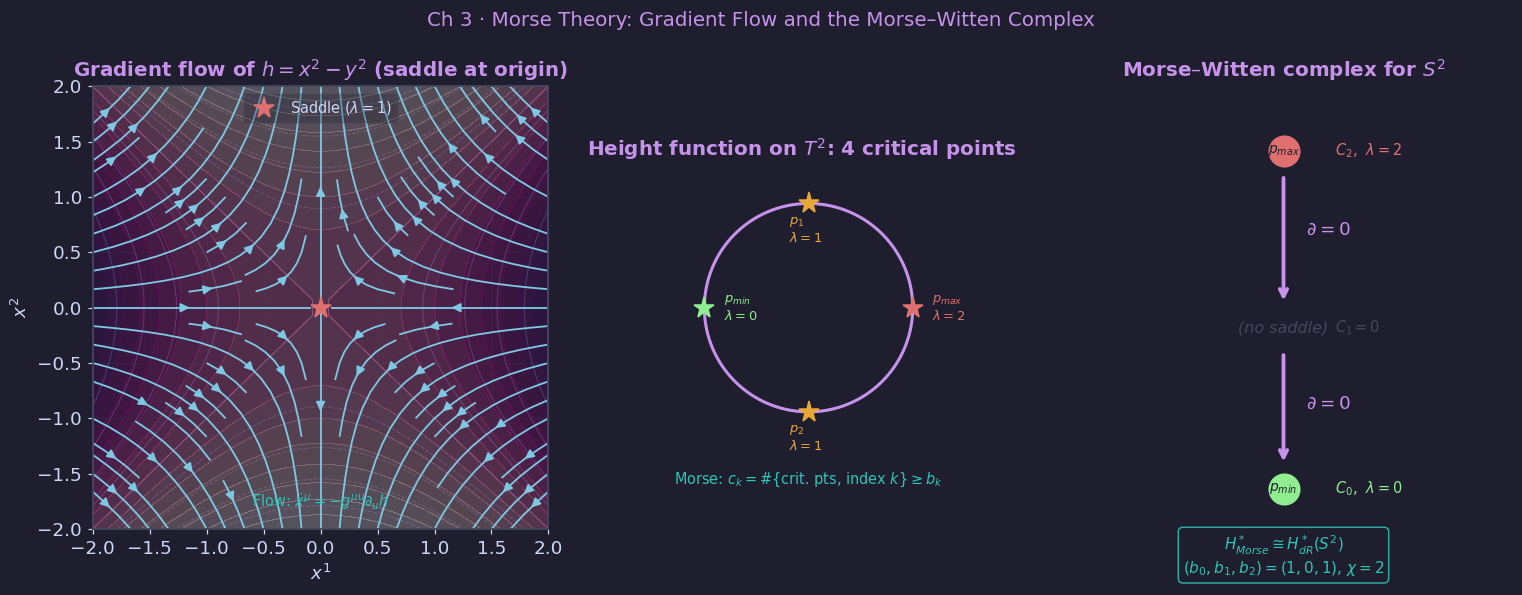

Saved: susyqm_figures/plot7_morse_theory.png


In [8]:
# ── Plot 7: Morse theory — gradient flow and Morse–Witten complex ─────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5.5))
fig.suptitle(r'Ch 3 · Morse Theory: Gradient Flow and the Morse–Witten Complex',
             color=PURP, fontsize=13)

# Panel 1: Morse function h(x,y) = x² - y² (saddle) with streamlines
ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'Gradient flow of $h=x^2-y^2$ (saddle at origin)', color=PURP)
xg = np.linspace(-2, 2, 30); yg = np.linspace(-2, 2, 30)
X, Y = np.meshgrid(xg, yg)
H  = X**2 - Y**2
dHx, dHy = 2*X, -2*Y    # gradient of h
ax.contourf(X, Y, H, levels=15, cmap='RdPu', alpha=0.25)
ax.contour(X, Y, H, levels=12, colors=[PURP], alpha=0.25, linewidths=0.7)
ax.streamplot(xg, yg, -dHx, -dHy,
              color=BLUE, density=0.85, arrowsize=1.2, linewidth=1.2)
ax.plot(0, 0, '*', color=RED, ms=14, zorder=8, label=r'Saddle ($\lambda=1$)')
ax.set_xlabel(r'$x^1$'); ax.set_ylabel(r'$x^2$')
ax.legend(fontsize=9.5); ax.grid(True, alpha=0.2)
ax.text(0, -1.8, r'Flow: $\dot x^\mu=-g^{\mu u}\partial_u h$',
        ha='center', fontsize=9.5, color=TEAL)

# Panel 2: torus height function — 4 critical points
ax = axes[1]; ax.set_facecolor(BG)
ax.set_title(r'Height function on $T^2$: 4 critical points', color=PURP)
theta_t = np.linspace(0, 2*np.pi, 300)
R, r = 1.5, 0.8
xT = (R + r*np.cos(theta_t))*np.cos(theta_t)  # schematic cross-section
yT = r * np.sin(theta_t)
ax.plot((R+r*np.cos(theta_t)), yT, color=PURP, lw=2)
ax.plot(-(R+r*np.cos(theta_t)), yT, color=PURP, lw=2, ls='--', alpha=0.4)

crit = [
    (R+r,  0,   'max',    r'$p_{max}$'+'\n'+r'$\lambda=2$',  RED,   2),
    (R,    r,   'saddle', r'$p_1$'+'\n'+r'$\lambda=1$',       ORAN,  1),
    (R,   -r,   'saddle', r'$p_2$'+'\n'+r'$\lambda=1$',       ORAN,  1),
    (R-r,  0,   'min',    r'$p_{min}$'+'\n'+r'$\lambda=0$',   GREEN, 0),
]
for i, (cx, cy, kind, lbl, col, morse_idx) in enumerate(crit):
    ax.plot(cx, cy, '*', color=col, ms=14, zorder=6)
    if i in [0, 3]:
        ax.text(cx+0.15, cy, lbl, fontsize=8.5, color=col, va='center')
    else:
        ax.text(cx-0.15, cy -0.20, lbl, fontsize=8.5, color=col, va='center')

ax.set_xlim(-0.3, 3.2); ax.set_ylim(-1.1, 1.1)
ax.set_aspect('equal'); ax.axis('off')
ax.text(1.5, -1.35,
        r'Morse: $c_k=$#{crit. pts, index $k$}$\geq b_k$',
        ha='center', fontsize=9.5, color=TEAL)

# Panel 3: Morse–Witten complex diagram
ax = axes[2]; ax.set_facecolor(BG)
ax.set_title(r'Morse–Witten complex for $S^2$', color=PURP)
ax.axis('off'); ax.set_xlim(0, 4); ax.set_ylim(-0.5, 5)

nodes = [
    (2.0, 4.2, r'$p_{max}$', r'$C_2$,  $\lambda=2$', RED),
    (2.0, 2.0, r'(no saddle)', r'$C_1=0$', EDGE),
    (2.0, 0.0, r'$p_{min}$', r'$C_0$,  $\lambda=0$', GREEN),
]
for nx, ny, nm, desc, col in nodes:
    if col == EDGE:
        ax.text(nx, ny, nm, ha='center', va='center', fontsize=10.5,
                color=EDGE, style='italic')
    else:
        ax.plot(nx, ny, 'o', color=col, ms=20, zorder=5)
        ax.text(nx, ny, nm, ha='center', va='center', fontsize=9, color=BG,
                fontweight='bold', zorder=6)
    ax.text(nx+0.45, ny, desc, fontsize=9.5, color=col, va='center')

# boundary maps
ax.annotate('', xy=(2, 2.3), xytext=(2, 3.9),
            arrowprops=dict(arrowstyle='->', color=PURP, lw=2.5))
ax.text(2.2, 3.15, r'$\partial=0$', fontsize=12, color=PURP)
ax.annotate('', xy=(2, 0.3), xytext=(2, 1.7),
            arrowprops=dict(arrowstyle='->', color=PURP, lw=2.5))
ax.text(2.2, 1.0, r'$\partial=0$', fontsize=12, color=PURP)

# result box
ax.text(0.5, -0.1,
        r'$H^*_{Morse}\cong H^*_{dR}(S^2)$' + '\n' +
        r'$(b_0,b_1,b_2)=(1,0,1)$, $\chi=2$',
        ha='center', fontsize=10, color=TEAL,
        bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=TEAL, alpha=0.85),
        transform=ax.transAxes)

plt.tight_layout()
savefig('plot7_morse_theory.png')


In [9]:
# ── Download all figures as a zip ────────────────────────────────────────────
import shutil
shutil.make_archive('susyqm_figures', 'zip', 'susyqm_figures')
try:
    from google.colab import files
    files.download('susyqm_figures.zip')
    print('Download triggered.')
except ImportError:
    print('Not in Colab — figures saved to susyqm_figures/')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered.
